<div align="center">

# Trabajo Práctico: Predicción de Lluva en Australia

**Aprendizaje Automático 1 — Tecnicatura en Inteligencia Artificial (FCEIA)**

</div>

---

**Integrantes:** 
* Aiup, Agustín.
* Paoloni, Franco.
* Silva, Julián.

---

# Librerías y Dataset

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)

In [58]:
clima_aus = pd.read_csv(("../data/weatherAUS_2026C2.csv"))

# 1. Análisis Exploratorio

A continuación se realiza un primer acercamiento a los datos.

In [59]:
print(f"Filas del Dataset: {clima_aus.shape[0]}. Columnas: {clima_aus.shape[1]}.")

Filas del Dataset: 145412. Columnas: 25.


In [60]:
clima_aus.head(10)

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2
5,5,2008-12-06,Albury,14.5,30.1,0.2,NaN,NaN,WNW,55.0,...,23.0,1009.9,1005.5,NaN,NaN,20.9,28.2,No,No,0.0
6,6,2008-12-07,Albury,15.1,25.3,0.0,NaN,NaN,W,51.0,...,20.3,1009.3,1008.5,1.0,NaN,18.3,24.0,No,No,0.0
7,7,2008-12-08,Albury,8.1,26.1,0.0,NaN,NaN,W,34.0,...,20.8,1013.5,1009.7,NaN,NaN,17.1,25.9,No,No,0.0
8,8,2008-12-09,Albury,9.5,31.8,0.0,NaN,NaN,NNW,80.0,...,8.5,1008.9,1003.6,NaN,NaN,18.0,28.9,No,Yes,1.4
9,9,2008-12-10,Albury,13.4,30.1,1.4,NaN,NaN,W,28.0,...,24.6,1007.2,1005.7,NaN,NaN,18.9,28.2,Yes,No,0.0


In [61]:
clima_aus.tail(10)

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
145402,145449,2017-06-15,Uluru,3.2,23.0,0.0,NaN,NaN,S,18.0,...,22.3,1025.0,1021.3,NaN,NaN,9.3,22.2,No,No,0.0
145403,145450,2017-06-16,Uluru,5.5,23.6,0.0,NaN,NaN,E,24.0,...,22.7,1024.2,1020.2,NaN,NaN,13.1,23.9,No,No,0.0
145404,145451,2017-06-17,Uluru,6.5,22.9,0.0,NaN,NaN,ESE,28.0,...,23.6,1025.9,1022.8,NaN,NaN,11.3,22.5,No,No,0.0
145405,145452,2017-06-18,Uluru,8.1,21.0,0.0,NaN,NaN,ESE,41.0,...,32.2,1027.9,1024.1,NaN,7.0,11.6,21.2,No,No,0.0
145406,145453,2017-06-19,Uluru,7.3,20.7,0.0,NaN,NaN,E,34.0,...,36.4,1027.4,1023.3,NaN,NaN,12.1,20.1,No,No,0.0
145407,145454,2017-06-20,Uluru,2.6,22.0,0.0,NaN,NaN,E,29.0,...,26.5,1024.8,1021.2,NaN,NaN,10.1,21.6,No,No,0.0
145408,145455,2017-06-21,Uluru,3.1,23.2,0.0,NaN,NaN,E,31.0,...,24.7,1024.3,1020.5,NaN,NaN,11.1,21.5,No,No,0.0
145409,145456,2017-06-22,Uluru,3.6,26.0,0.0,NaN,NaN,NNW,21.0,...,21.4,1023.3,1018.4,NaN,NaN,11.8,24.5,No,No,0.0
145410,145457,2017-06-23,Uluru,4.8,27.4,0.0,NaN,NaN,N,39.0,...,23.7,1021.0,1016.0,NaN,NaN,12.0,26.9,No,No,0.0
145411,145458,2017-06-24,Uluru,7.5,26.5,0.0,NaN,NaN,SE,28.0,...,27.1,1019.8,1016.2,3.0,2.0,14.7,26.8,No,No,0.0


In [62]:
clima_aus.info()

<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        145412 non-null  int64  
 1   Date              145412 non-null  str    
 2   Location          145412 non-null  str    
 3   MinTemp           143928 non-null  float64
 4   MaxTemp           144159 non-null  float64
 5   Rainfall          142152 non-null  float64
 6   Evaporation       82658 non-null   float64
 7   Sunshine          75616 non-null   float64
 8   WindGustDir       135096 non-null  str    
 9   WindGustSpeed     135159 non-null  float64
 10  WindDir9am        134850 non-null  str    
 11  WindDir3pm        141186 non-null  str    
 12  WindSpeed9am      143645 non-null  float64
 13  WindSpeed3pm      142351 non-null  float64
 14  Humidity9am       142759 non-null  float64
 15  Humidity3pm       140907 non-null  float64
 16  Pressure9am       130351 non-nu

Se elimina la columna duplicada `Unnamed: 0`.

In [63]:
clima_aus = clima_aus.drop(columns=['Unnamed: 0'])

Dividimos las columnas en numéricas y de texto.

In [64]:
columnas_num = clima_aus.select_dtypes(include="number")
columnas_str = clima_aus.select_dtypes(include="str")

Se analiza la distribución de las variables numéricas.

In [65]:
print(f"Columnas numéricas => Filas: {columnas_num.shape[0]}. Columnas: {columnas_num.shape[1]}.")

Columnas numéricas => Filas: 145412. Columnas: 17.


In [66]:
desc = columnas_num.describe().T
desc['mediana'] = columnas_num.median()
desc['CV(%)'] = (desc['std'] / desc['mean']) * 100
desc['sesgo'] = columnas_num.skew()
desc['curtosis'] = columnas_num.kurtosis()


desc[['mean', 'mediana', 'std', 'CV(%)', 'min', '25%', '50%', '75%', 'max',
      'sesgo', 'curtosis']]

,mean,mediana,std,CV(%),min,25%,50%,75%,max,sesgo,curtosis
MinTemp,12.196528,12.0,6.417956,52.621169,-9.7,7.6,12.0,16.9,34.1,0.019449,-0.478637
MaxTemp,23.223064,22.6,7.135927,30.727759,-5.1,17.9,22.6,28.2,49.1,0.218606,-0.221082
Rainfall,2.361516,0.0,8.479338,359.063354,0.0,0.0,0.0,0.8,371.0,9.834819,178.099955
Evaporation,5.468616,4.8,4.193871,76.689792,0.0,2.6,4.8,7.4,145.0,3.761159,45.041191
Sunshine,7.611241,8.4,3.785612,49.737121,0.0,4.8,8.4,10.6,14.5,-0.496503,-0.829508
WindGustSpeed,40.036668,38.0,13.648259,34.089399,6.0,31.0,38.0,48.0,135.0,0.867216,1.402022
WindSpeed9am,14.067277,13.0,8.936768,63.528769,0.0,7.0,13.0,19.0,130.0,0.787317,1.219027
WindSpeed3pm,18.661899,18.0,8.865457,47.505651,0.0,12.0,18.0,24.0,86.0,0.616980,0.730063
Humidity9am,68.861521,69.9,19.062866,27.682901,0.0,57.0,69.9,83.1,100.0,-0.486012,-0.042284
Humidity3pm,51.532206,52.0,20.844414,40.449296,0.0,36.6,52.0,65.7,100.0,0.031449,-0.509916


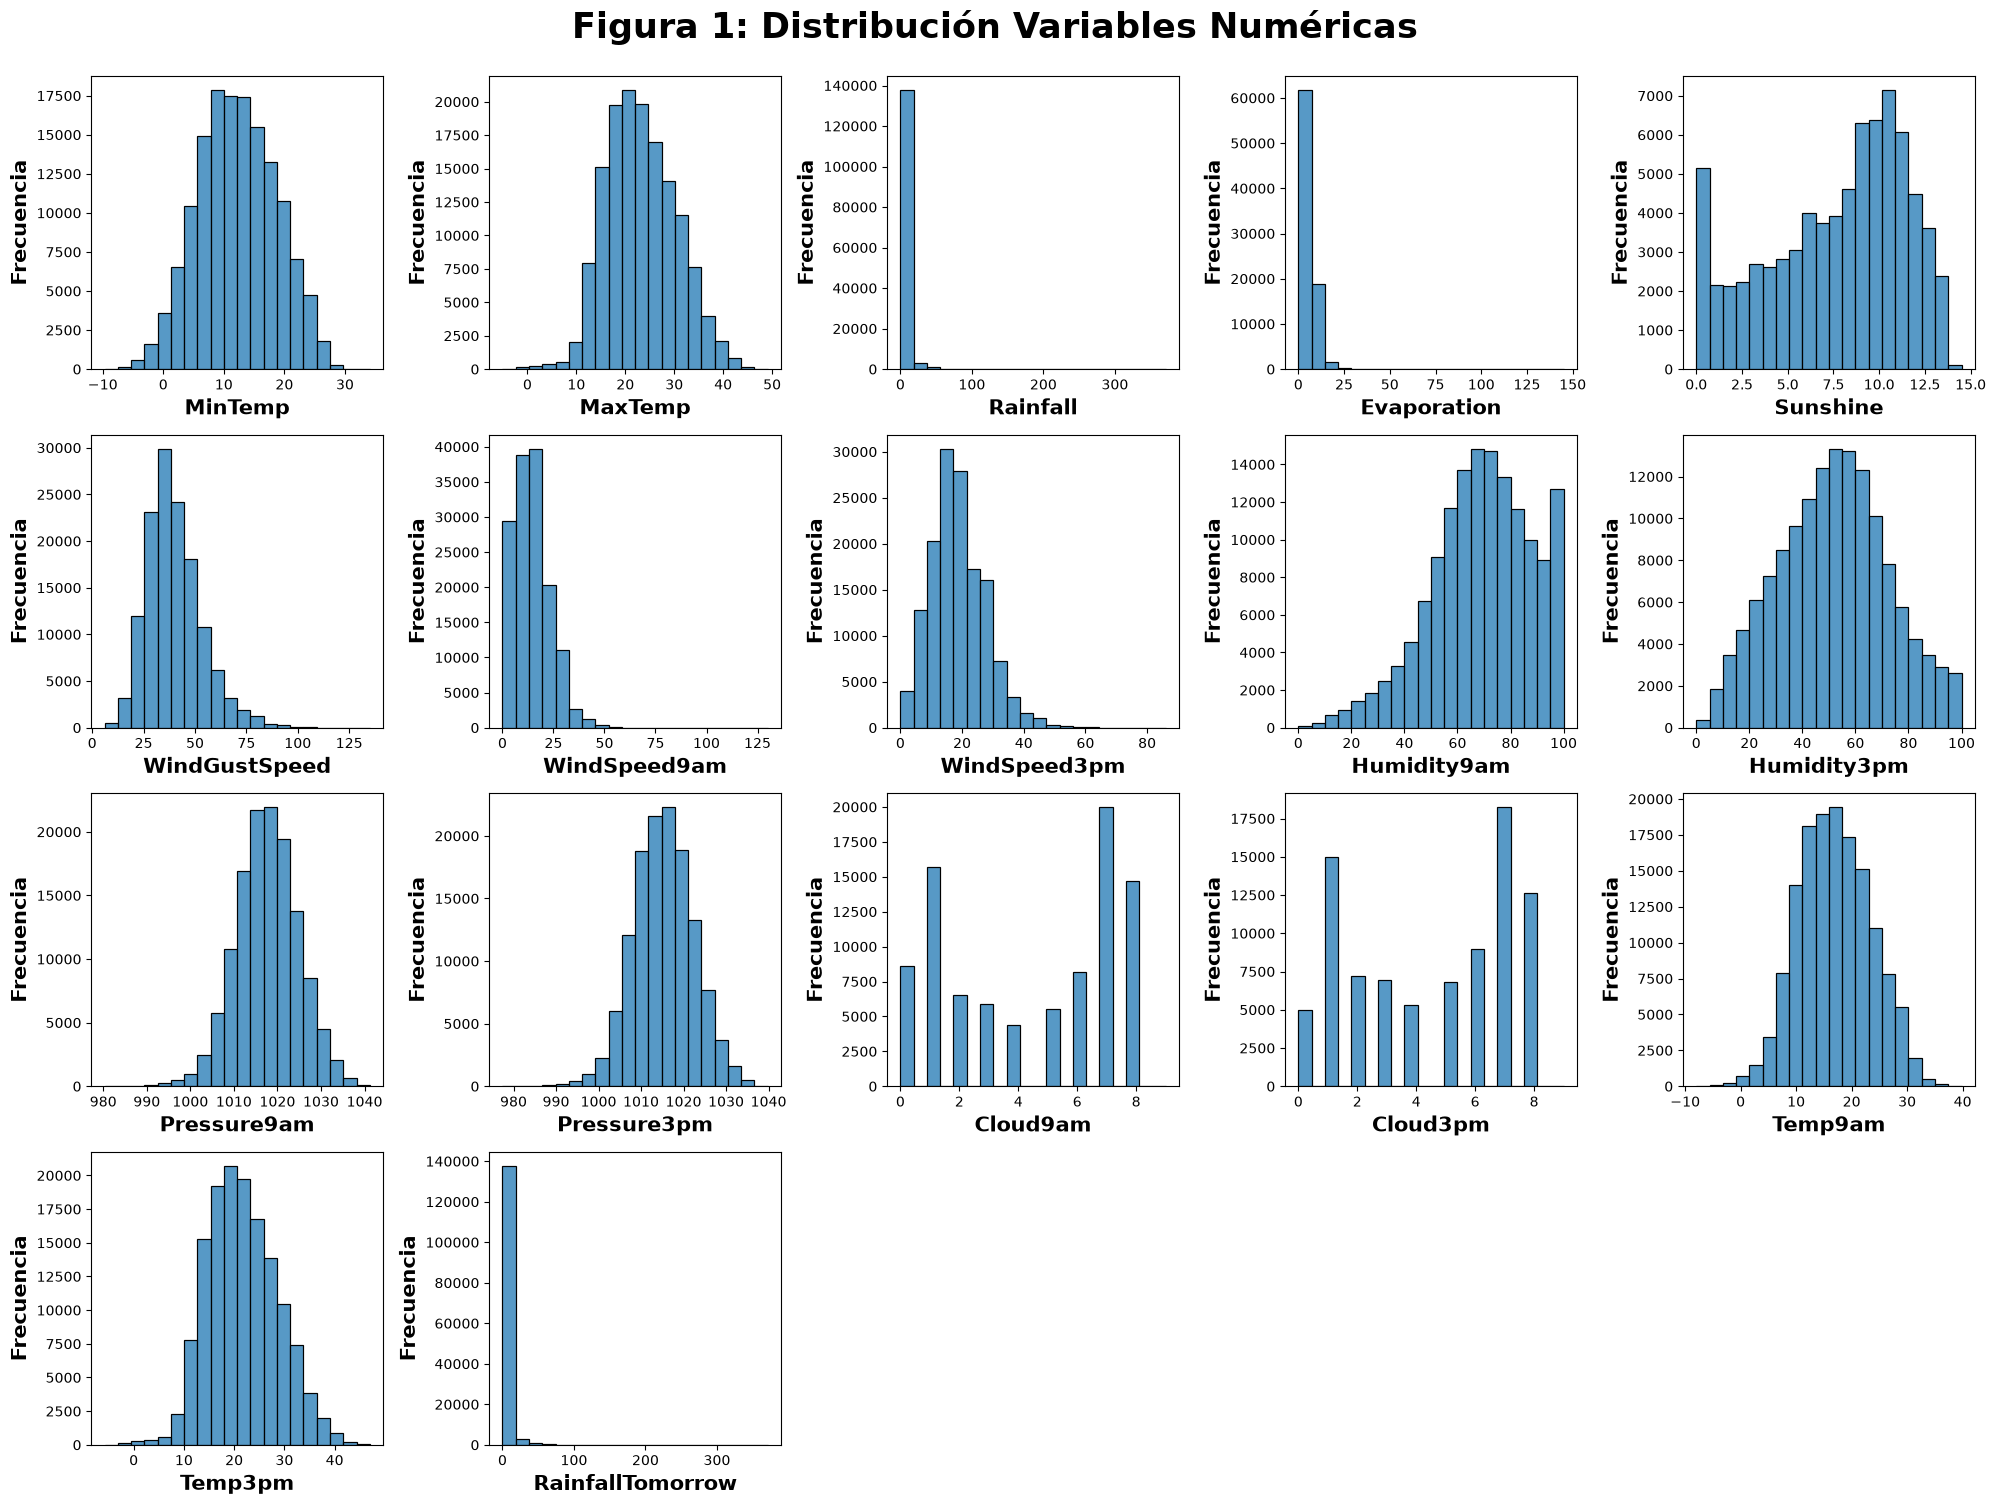

In [67]:
fig, axes = plt.subplots(ncols = 5, nrows = 4, figsize = (20, 15))
axes = axes.flatten()

for ax, columna in zip(axes, columnas_num.columns):
    sns.histplot(columnas_num, x = columna, ax = ax, bins = 20)
    ax.set_ylabel('Frecuencia', fontweight = 'bold', fontsize = 15)
    ax.set_xlabel(columna, fontweight = 'bold', fontsize = 15)

for i in range(len(columnas_num.columns), len(axes)):
    axes[i].set_visible(False)

plt.suptitle('Figura 1: Distribución Variables Numéricas', fontweight = 'bold', fontsize = 25, y = 1)
plt.tight_layout()
plt.show()

Se analiza con mayor detenimiento las columnas `Cloud9am` y `Cloud3pm`. 

In [68]:
columnas_num['Cloud9am'].value_counts(dropna=False)

Cloud9am
NaN    55870
7.0    19965
1.0    15680
8.0    14690
0.0     8641
6.0     8168
2.0     6500
3.0     5912
5.0     5566
4.0     4418
9.0        2
Name: count, dtype: int64

In [69]:
columnas_num['Cloud3pm'].value_counts(dropna=False)

Cloud3pm
NaN    59336
7.0    18226
1.0    14972
8.0    12650
6.0     8978
2.0     7224
3.0     6915
5.0     6815
4.0     5321
0.0     4974
9.0        1
Name: count, dtype: int64

In [70]:
columnas_num[columnas_num['Cloud3pm'] == 9.0]

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainfallTomorrow
106899,11.4,23.8,0.2,11.6,11.4,39.0,27.0,15.0,45.4,13.3,1019.0,1014.9,6.0,9.0,14.3,23.7,0.0


In [71]:
columnas_num[columnas_num['Cloud9am'] == 9.0]

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainfallTomorrow
30767,16.9,21.2,4.4,11.2,8.0,NaN,30.0,36.0,38.7,35.6,997.4,998.2,9.0,3.0,16.1,20.9,0.0
47212,0.5,13.5,0.0,NaN,7.8,28.0,5.0,8.0,98.6,43.4,1022.4,1020.6,9.0,NaN,5.1,14.2,0.0


Se desprende que, las columnas `Cloud9am` y `Cloud3pm`, son en realidad columnas numéricas Estas representan la fracción del cielo cubierta por nubes a las 9 a. m. y 3 p. m., respectivamente, medida en octas (octavos): 0 es cielo despejado y 8 totalmente cubierto.

Luego los analizaremos por separado.

In [72]:
columnas_cat = columnas_num[['Cloud9am', 'Cloud3pm']]
columnas_num = columnas_num.drop(columns = ['Cloud9am', 'Cloud3pm'])

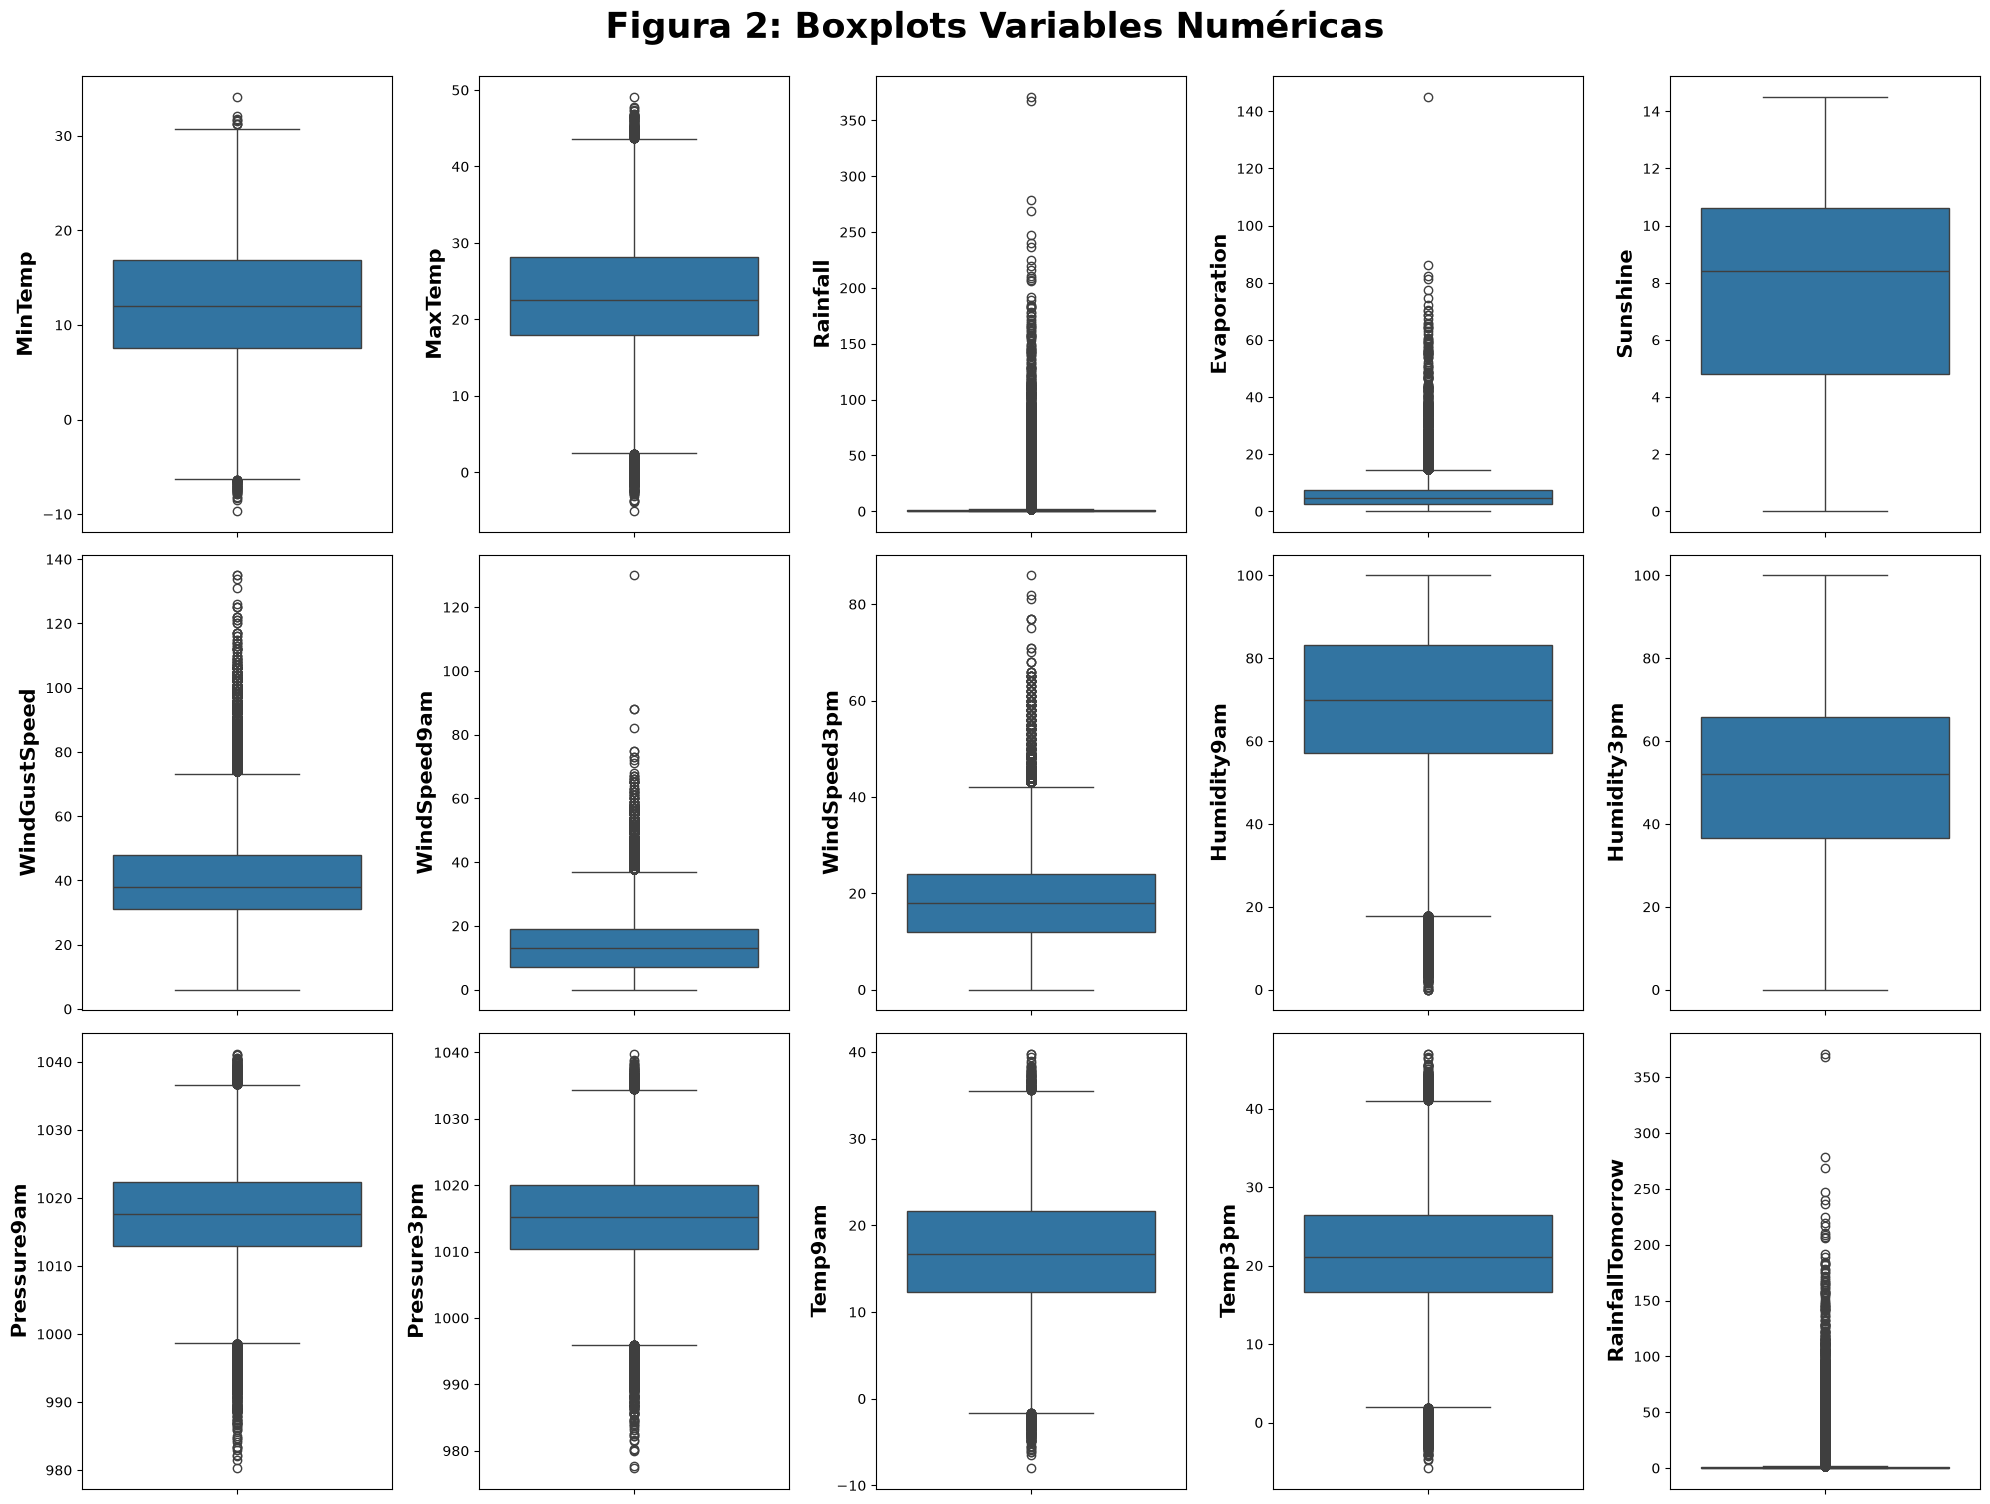

In [73]:
fig, axes = plt.subplots(ncols=5, nrows=3, figsize=(20, 15))
axes = axes.flatten()

for ax, columna in zip(axes, columnas_num.columns):
    sns.boxplot(columnas_num, y=columna, ax=ax)
    ax.set_ylabel(columna, fontweight = 'bold', fontsize = 15)

for i in range(len(columnas_num.columns), len(axes)):
    axes[i].set_visible(False)

plt.suptitle('Figura 2: Boxplots Variables Numéricas', fontweight = 'bold', fontsize = 25, y=1)
plt.tight_layout()
plt.show()

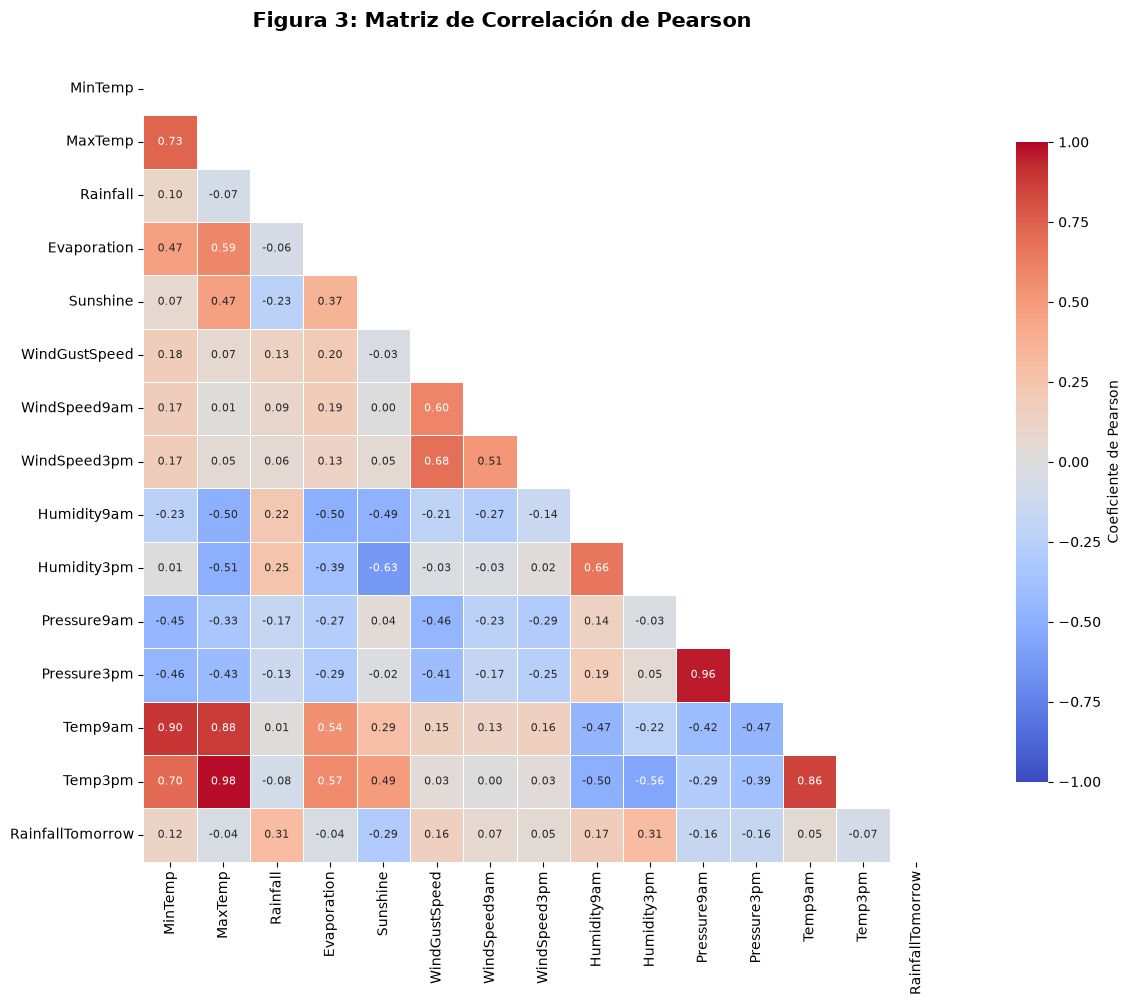

In [74]:
matriz_correlacion = columnas_num.corr(method = 'pearson')
mascara = np.triu(np.ones_like(matriz_correlacion, dtype = bool))

fig, ax = plt.subplots(figsize = (15, 10))

sns.heatmap(matriz_correlacion, mask = mascara, annot = True, fmt = '.2f',
            annot_kws = {'size' : 8}, cmap = 'coolwarm', vmin = -1, vmax = 1,
            center = 0, square = True, linewidths = 0.5,
            cbar_kws = {'shrink' : 0.8, 'label' : 'Coeficiente de Pearson'}, ax = ax)

plt.suptitle('Figura 3: Matriz de Correlación de Pearson', fontweight = 'bold', fontsize = 15, y=1)
plt.tight_layout()
plt.show()

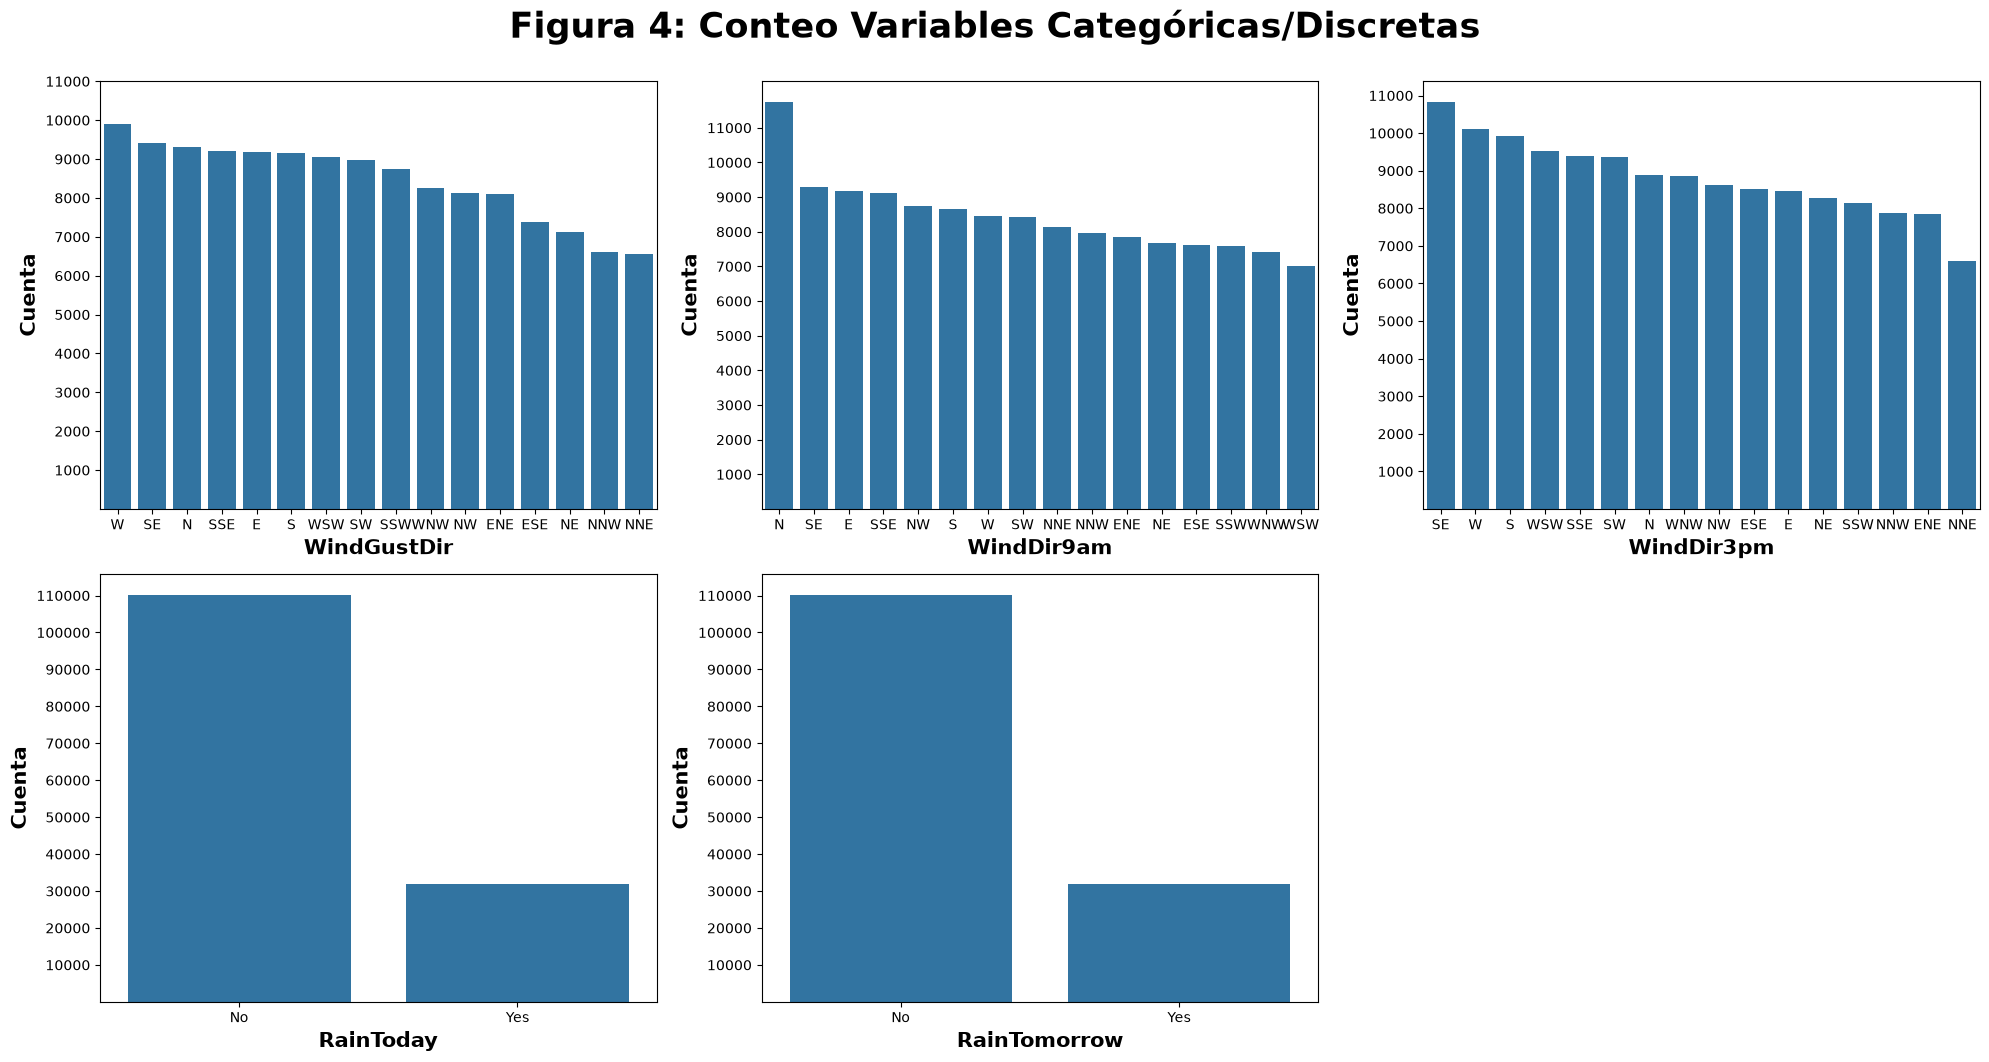

In [75]:
fig, axes = plt.subplots(ncols=3, nrows=3, figsize = (20, 15))
axes = axes.flatten()

columnas_fig_4 = columnas_str.drop(columns=['Date','Location'])

for ax, columna in zip(axes, columnas_fig_4.columns):

    if columna in ['WindGustDir', 'WindDir9am', 'WindDir3pm']:
        sns.countplot(columnas_str, x=columna, ax=ax, order=columnas_fig_4[columna].value_counts().index)
        ax.set_ylabel('Cuenta', fontweight = 'bold', fontsize = 15)
        ax.set_yticks((np.arange(1000, 12000, 1000)))
        ax.set_xlabel(columna, fontweight = 'bold', fontsize = 15)

    elif columna in ['RainToday', 'RainTomorrow']:
        sns.countplot(columnas_str, x=columna, ax=ax)
        ax.set_ylabel('Cuenta', fontweight = 'bold', fontsize = 15)
        ax.set_yticks((np.arange(10000, 120000, 10000)))
        ax.set_xlabel(columna, fontweight = 'bold', fontsize = 15)

for i in range(len(columnas_fig_4.columns), len(axes)):
    axes[i].set_visible(False)

plt.suptitle('Figura 4: Conteo Variables Categóricas/Discretas', fontweight = 'bold', fontsize = 25, y = 1)
plt.tight_layout()
plt.show()

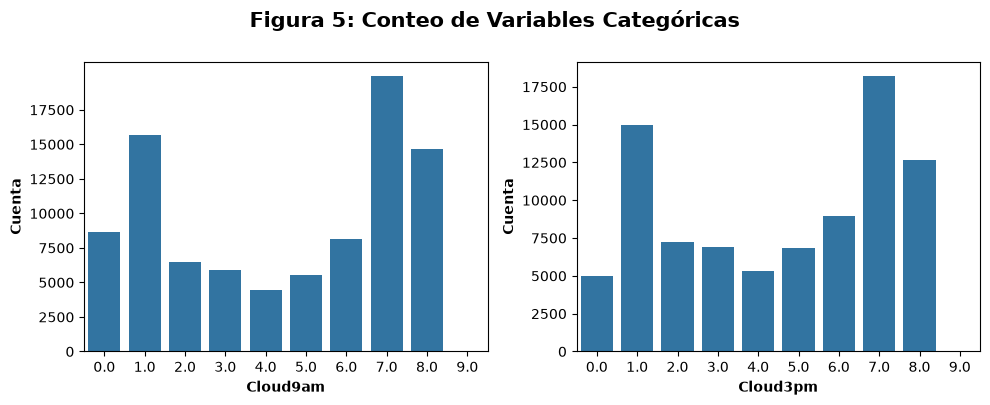

In [76]:
fig, axes = plt.subplots(ncols=2, nrows=1, figsize=(10, 4))
axes = axes.flatten()

for ax, columna in zip(axes, columnas_cat.columns):
    sns.countplot(columnas_cat, x = columna, ax = ax)
    ax.set_ylabel('Cuenta', fontweight = 'bold', fontsize = 10)
    ax.set_yticks((np.arange(0, 20000, 2500)))
    ax.set_xlabel(columna, fontweight = 'bold', fontsize = 10)
    
plt.suptitle('Figura 5: Conteo de Variables Categóricas', fontweight = 'bold', fontsize = 15, y = 1)
plt.tight_layout()
plt.show()    

## Procesamiento de Datos

En la siguiente sección, se realizarán un conjunto de prácticas para identificar, corregir, eliminar o estimar valores ausentes, errores, duplicados y datos atípicos.

### Limpieza de Datos

1. En el análisis exploratorio se observa que hay una columna denominada `RainfallTomorrow`. Dicha variable muestra la cantidad de lluvia caida en el día de mañana. Para valores mayores a 1, coincide con la información que muestra `RainTomorrow`. Si esta variable queda como predictora, el modelo estaría usando "información del futuro" para entrenarse. Por lo tanto, se procede a eliminarla del dataset.

In [77]:
clima_aus.loc[clima_aus['RainfallTomorrow'] > 1, ['RainTomorrow', 'RainfallTomorrow']].sort_values(by = 'RainTomorrow').reset_index(drop=True)['RainTomorrow'].value_counts()

RainTomorrow
Yes    31872
Name: count, dtype: int64

In [78]:
clima_aus = clima_aus.drop(columns=['RainfallTomorrow'])

2. Se modifican los valores inconsistentes para las columnas `Cloud3pm` y `Cloud9am`, para luego trabajarlos como faltantes.

In [79]:
clima_aus['Cloud3pm'] = clima_aus['Cloud3pm'].replace(9.0, np.nan)
clima_aus['Cloud9am'] = clima_aus['Cloud9am'].replace(9.0, np.nan)

3. Siguiendo la línea de `RainfallTomorrow` y `RainTomorrow`, las filas `Rainfall` y `RainToday` coinciden para valores de lluvia mayores a 1. Mantener ambas no agrega mayor información a la hora de entrenar el modelo. Dado que la primera de estas variables es más completa que la segunda, se mantiene en el dataset, mientras que `RainToday` se descarta.

In [80]:
clima_aus = clima_aus.drop(columns=['RainToday'])

4. La columna `Date` por sí misma no sirve como predictora. En su lugar, nos quedaremos con el mes para cada fecha.

In [81]:
clima_aus['Date'] = pd.to_datetime(clima_aus['Date'])
clima_aus['Month'] = clima_aus['Date'].dt.month
clima_aus = clima_aus.sort_values('Date')

5. Se eliminan las observaciones donde `RainTomorrow` es nula.

In [82]:
print(f"Cantidad de nulos para la variable 'RainTomorrow': {clima_aus['RainTomorrow'].isna().sum()}.")
clima_aus = clima_aus.dropna(subset='RainTomorrow')
print(f"El dataset ahora tiene {clima_aus.shape[0]} filas.")

Cantidad de nulos para la variable 'RainTomorrow': 3259.
El dataset ahora tiene 142153 filas.


### División Train - Test

Se realiza la división del dataset, previo a generar imputaciones, balancear variables, etc. En este caso, se suma tambien un set de validacion.


In [83]:
val_cutoff = pd.Timestamp('2015-01-01')
test_cutoff = pd.Timestamp('2016-01-01')

train_mask = clima_aus['Date'] < val_cutoff
val_mask = (clima_aus['Date'] >= val_cutoff) & (clima_aus['Date'] < test_cutoff)
test_mask = clima_aus['Date'] >= test_cutoff

X = clima_aus.drop(columns=['RainTomorrow', 'Date'])
y = clima_aus['RainTomorrow']

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

### Tratamiento de datos faltantes

Primero contamos los faltantes de las variables predictoras en cada partición. Esto permite ver si hay columnas especialmente incompletas y cuánto se perdería si elimináramos filas.


In [84]:
resumen_faltantes = pd.DataFrame({
    'Train (n)': X_train.isna().sum(),
    'Train (%)': X_train.isna().mean() * 100,
    'Validación (n)': X_val.isna().sum(),
    'Validación (%)': X_val.isna().mean() * 100,
    'Test (n)': X_test.isna().sum(),
    'Test (%)': X_test.isna().mean() * 100
}).sort_values('Train (%)', ascending=False)

print(f"Filas de train con al menos un faltante: {X_train.isna().any(axis=1).sum()} de {len(X_train)}.")
resumen_faltantes.round(2)

Filas de train con al menos un faltante: 55168 de 98988.


,Train (n),Train (%),Validación (n),Validación (%),Test (n),Test (%)
Sunshine,40696,41.11,9165,53.19,17924,69.11
Evaporation,37110,37.49,8463,49.11,15239,58.76
Cloud3pm,36767,37.14,7019,40.73,13291,51.25
Cloud9am,35766,36.13,6593,38.26,11284,43.51
Pressure9am,9345,9.44,1989,11.54,2676,10.32
Pressure3pm,9309,9.40,1987,11.53,2681,10.34
WindDir9am,7323,7.40,1114,6.47,1572,6.06
WindGustDir,6943,7.01,927,5.38,1458,5.62
WindGustSpeed,6902,6.97,908,5.27,1458,5.62
WindDir3pm,2030,2.05,520,3.02,1226,4.73


Se pocede a imputar los datos faltantes. Para ello se utiliza:

- **Variables numéricas:** mediana de train, porque es menos sensible a valores extremos que el promedio.
- **Variables categóricas:** categoría más frecuente de train, para conservar valores válidos de cada variable.

Se utilizan las medidas globales y no por `Location`, dado que hay lugares que nunca midió alguna de las variables, lo que obliga a usar el "imputador general". Además, se hicieron las pruebas necesarias y se determinó que al determinar por ciudad el modelo no mejoró de forma apreciable.

In [85]:
columnas_numericas = X_train.select_dtypes(include='number').columns
columnas_categoricas = X_train.select_dtypes(exclude='number').columns

medianas_train = X_train[columnas_numericas].median()
modas_train = X_train[columnas_categoricas].mode(dropna=True).iloc[0]

X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

for conjunto in (X_train, X_val, X_test):
    conjunto[columnas_numericas] = conjunto[columnas_numericas].fillna(medianas_train)
    conjunto[columnas_categoricas] = conjunto[columnas_categoricas].fillna(modas_train)

print(f"Faltantes restantes en train: {X_train.isna().sum().sum()}.")
print(f"Faltantes restantes en validación: {X_val.isna().sum().sum()}.")
print(f"Faltantes restantes en test: {X_test.isna().sum().sum()}.")

Faltantes restantes en train: 0.
Faltantes restantes en validación: 0.
Faltantes restantes en test: 0.


Después de esta etapa, los tres conjuntos de predictores quedan completos. La imputación conserva las observaciones y mantiene separado el aprendizaje de los valores de reemplazo. En las siguientes etapas todavía habrá que codificar las categorías para que los modelos puedan utilizarlas.


### Balance de clases

Se analiza la proporción de cada clase de `RainTomorrow` en los tres conjuntos.

In [86]:
balance = pd.DataFrame({
    'Train (%)': y_train.value_counts(normalize = True) * 100,
    'Validación (%)': y_val.value_counts(normalize = True) * 100,
    'Test (%)': y_test.value_counts(normalize = True) * 100
})

balance.round(2)

,Train (%),Validación (%),Test (%)
RainTomorrow,,,
No,77.49,78.83,77.09
Yes,22.51,21.17,22.91


El dataset está desbalanceado: en train, solo el 22,5% de los días llueve al día siguiente. Las proporciones se mantienen parecidas en validación (21,2%) y en test (22,9%).

La pregunta es importante porque un modelo que prediga siempre "No" acertaría cerca del 78% de las veces sin haber aprendido nada. Por eso la accuracy sola no alcanza para evaluar los modelos, y se usarán también métricas que miran cómo le va con la clase minoritaria, como precision, recall, F1 y el área bajo la curva ROC.

### Codificación de variables categóricas

Los modelos necesitan valores numéricos, por lo que se codifican las variables de texto y el mes:

- `Location`: one-hot. Las 49 ciudades no tienen un orden entre sí, así que no se les puede asignar un número.
- `WindGustDir`, `WindDir9am` y `WindDir3pm`: one-hot, una columna por cada una de las 16 direcciones.
- `Month`: seno y coseno del ángulo del mes. Si se dejara como número del 1 al 12, el modelo vería a diciembre y enero como los meses más lejanos, cuando en realidad son consecutivos. Con seno y coseno cada mes queda como un punto en un círculo y diciembre queda al lado de enero.
- `RainTomorrow`: "Yes" pasa a 1 y "No" a 0.

El codificador se ajusta solo con train. Con `handle_unknown = 'ignore'`, si en validación o test aparece una categoría que no estaba en train, sus columnas quedan en 0 en lugar de dar error.

In [87]:
columnas_one_hot = ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm']

codificador = OneHotEncoder(handle_unknown = 'ignore', sparse_output = False)
codificador.fit(X_train[columnas_one_hot])

def codificar(conjunto):
    dummies = pd.DataFrame(codificador.transform(conjunto[columnas_one_hot]),
                           columns = codificador.get_feature_names_out(columnas_one_hot),
                           index = conjunto.index)
    conjunto = pd.concat([conjunto.drop(columns = columnas_one_hot), dummies], axis = 1)

    # El mes se ubica en un círculo: 12 meses = 2*pi
    conjunto['Month_sin'] = np.sin(2 * np.pi * conjunto['Month'] / 12)
    conjunto['Month_cos'] = np.cos(2 * np.pi * conjunto['Month'] / 12)
    return conjunto.drop(columns = 'Month')

X_train_cod = codificar(X_train)
X_val_cod = codificar(X_val)
X_test_cod = codificar(X_test)

y_train_cod = (y_train == 'Yes').astype(int)
y_val_cod = (y_val == 'Yes').astype(int)
y_test_cod = (y_test == 'Yes').astype(int)

print(f"Columnas después de codificar: {X_train_cod.shape[1]}.")

Columnas después de codificar: 115.


Después de codificar quedan 115 columnas: las 16 numéricas originales, 97 columnas one-hot (49 de `Location` y 16 por cada dirección de viento) y las 2 del mes.

### Escalado

Se estandarizan las variables numéricas con `StandardScaler`, ajustado solo con train y aplicado después a validación y test, igual que en el TP de regresión. Las columnas one-hot no se escalan porque ya valen 0 o 1.

In [88]:
columnas_escalar = list(columnas_numericas.drop('Month')) + ['Month_sin', 'Month_cos']

escalador = StandardScaler()

X_train_esc = X_train_cod.copy()
X_val_esc = X_val_cod.copy()
X_test_esc = X_test_cod.copy()

X_train_esc[columnas_escalar] = escalador.fit_transform(X_train_cod[columnas_escalar])
X_val_esc[columnas_escalar] = escalador.transform(X_val_cod[columnas_escalar])
X_test_esc[columnas_escalar] = escalador.transform(X_test_cod[columnas_escalar])

# 2. Regresión Logística

Se entrenan dos modelos de regresión logística:

- **Regresión logística estándar**, con los parámetros por defecto.
- **Regresión logística balanceada**, con `class_weight = 'balanced'`. Esta opción le da más peso a los errores sobre la clase minoritaria: cada día de lluvia pesa en el entrenamiento como si fueran unos 3,4 días sin lluvia (la proporción entre ambas clases en train). Así el modelo no se inclina tanto a predecir "No".

Ambos se entrenan con train y se evalúan en validación. El conjunto de test se reserva para la comparación final de modelos.

In [89]:
modelos_logisticos = {
    'Logística estándar': LogisticRegression(max_iter = 1000),
    'Logística balanceada': LogisticRegression(max_iter = 1000, class_weight = 'balanced')
}

for modelo in modelos_logisticos.values():
    modelo.fit(X_train_esc, y_train_cod)

### Métricas

Se calculan las siguientes métricas, considerando "lluvia" como la clase positiva:

- **Accuracy**: proporción de predicciones correctas. Por el desbalance, por sí sola no es confiable.
- **Precision**: de los días en que el modelo predijo lluvia, qué proporción realmente llovió.
- **Recall**: de los días en que llovió, qué proporción detectó el modelo.
- **F1**: media armónica entre precision y recall. Solo es alta si ambas lo son.
- **Balanced accuracy**: promedio del recall de cada clase. A diferencia de la accuracy, un modelo que siempre dice "No" obtiene 0,5.
- **AUC-ROC**: área bajo la curva ROC. Mide qué tan bien el modelo ordena los días según la probabilidad de lluvia, sin depender del umbral elegido.
- **AUC-PR** (average precision): área bajo la curva precision-recall. Es más exigente que la AUC-ROC cuando la clase positiva es minoritaria, porque no se ve inflada por la gran cantidad de días sin lluvia.

Las primeras cinco dependen del umbral con el que se pasa de probabilidad a clase. Por ahora se usa 0,5, que es el valor por defecto.

In [90]:
def calcular_metricas(y_real, probabilidades, umbral = 0.5):
    y_predicho = (probabilidades >= umbral).astype(int)
    return {
        'Accuracy': accuracy_score(y_real, y_predicho),
        'Precision': precision_score(y_real, y_predicho, zero_division = 0),
        'Recall': recall_score(y_real, y_predicho),
        'F1': f1_score(y_real, y_predicho),
        'Balanced accuracy': balanced_accuracy_score(y_real, y_predicho),
        'AUC-ROC': roc_auc_score(y_real, probabilidades),
        'AUC-PR': average_precision_score(y_real, probabilidades)
    }

# Probabilidad de lluvia que asigna cada modelo en train y validación
probabilidades = {
    nombre: {
        'Train': modelo.predict_proba(X_train_esc)[:, 1],
        'Validación': modelo.predict_proba(X_val_esc)[:, 1]
    }
    for nombre, modelo in modelos_logisticos.items()
}

metricas_logisticas = pd.DataFrame({
    (nombre, conjunto): calcular_metricas(y_train_cod if conjunto == 'Train' else y_val_cod, proba)
    for nombre, probas in probabilidades.items()
    for conjunto, proba in probas.items()
})

metricas_logisticas.round(3)

Logística estándar            Logística balanceada  \
                               Train Validación                Train   
Accuracy                       0.849      0.852                0.794   
Precision                      0.732      0.747                0.529   
Recall                         0.516      0.455                0.779   
F1                             0.606      0.565                0.630   
Balanced accuracy              0.731      0.707                0.789   
AUC-ROC                        0.873      0.870                0.873   
AUC-PR                         0.707      0.687                0.703   

                              
                  Validación  
Accuracy               0.812  
Precision              0.543  
Recall                 0.727  
F1                     0.621  
Balanced accuracy      0.781  
AUC-ROC                0.871  
AUC-PR                 0.684

Con el umbral de 0,5, la regresión logística estándar tiene la mejor accuracy (0,852 en validación), pero su recall es de apenas 0,455: **no detecta más de la mitad de los días de lluvia**. Es el efecto del desbalance: el modelo aprendió que decir "No" suele ser lo correcto.

La versión balanceada sacrifica algo de accuracy (0,812) y de precision, pero sube el recall a 0,727 y obtiene un F1 mayor (0,621 contra 0,565).

La AUC-ROC es la misma en ambos modelos (0,87), y la AUC-PR también es casi igual. Como estas métricas no dependen del umbral, esto indica que los dos modelos **ordenan los días de la misma manera**: la diferencia está en dónde ubican el corte entre "llueve" y "no llueve". Se retoma al analizar el umbral.

### Matrices de confusión

Se grafican las matrices de confusión de ambos modelos en validación, con umbral 0,5.

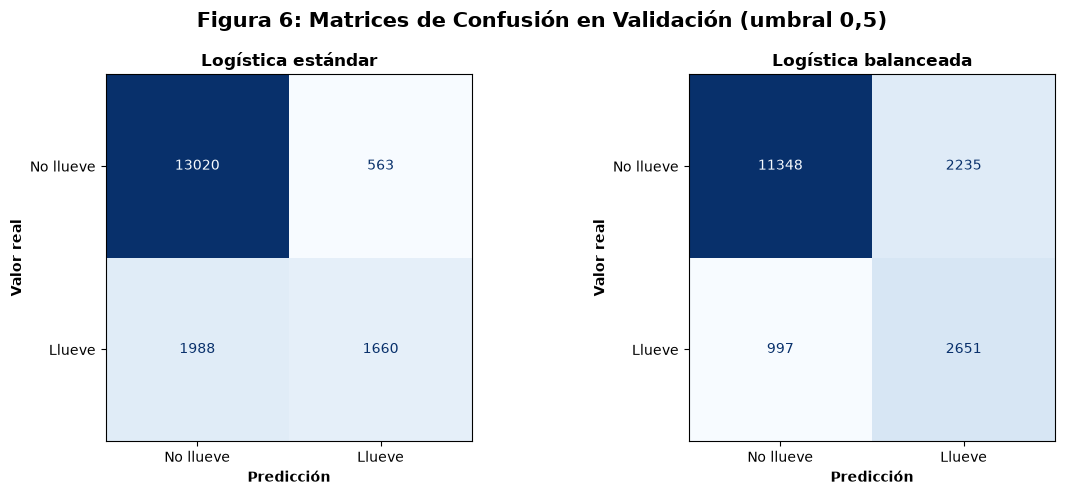

In [91]:
fig, axes = plt.subplots(ncols = 2, nrows = 1, figsize = (12, 5))

for ax, (nombre, probas) in zip(axes, probabilidades.items()):
    y_predicho = (probas['Validación'] >= 0.5).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_val_cod, y_predicho),
                           display_labels = ['No llueve', 'Llueve']).plot(ax = ax, cmap = 'Blues', colorbar = False, values_format = 'd')
    ax.set_title(nombre, fontweight = 'bold')
    ax.set_xlabel('Predicción', fontweight = 'bold')
    ax.set_ylabel('Valor real', fontweight = 'bold')

plt.suptitle('Figura 6: Matrices de Confusión en Validación (umbral 0,5)', fontweight = 'bold', fontsize = 15)
plt.tight_layout()
plt.show()

En este problema:

- **Falso negativo**: el modelo predice que mañana no llueve, pero llueve. Es el error de quien sale sin paraguas o del productor que no protege su cosecha.
- **Falso positivo**: el modelo predice lluvia, pero no llueve. Es una falsa alarma: se toman precauciones que no hacían falta.

Para un pronóstico de lluvia, en general el falso negativo es el error más costoso, porque toma desprevenido a quien confió en el pronóstico, mientras que una falsa alarma solo genera una molestia.

La regresión logística estándar comete 1.988 falsos negativos y solo 563 falsos positivos: se equivoca casi siempre del lado de "no llueve". La balanceada reduce los falsos negativos a la mitad (997), a cambio de casi cuadruplicar las falsas alarmas (2.235). Ninguno de los dos es mejor en términos absolutos: cuál conviene depende de cuánto cuesta cada tipo de error.

### Curvas ROC

La curva ROC muestra, para todos los umbrales posibles, la tasa de verdaderos positivos (recall) contra la tasa de falsos positivos (proporción de días sin lluvia que el modelo marcó como lluvia). La diagonal corresponde a un modelo que predice al azar.

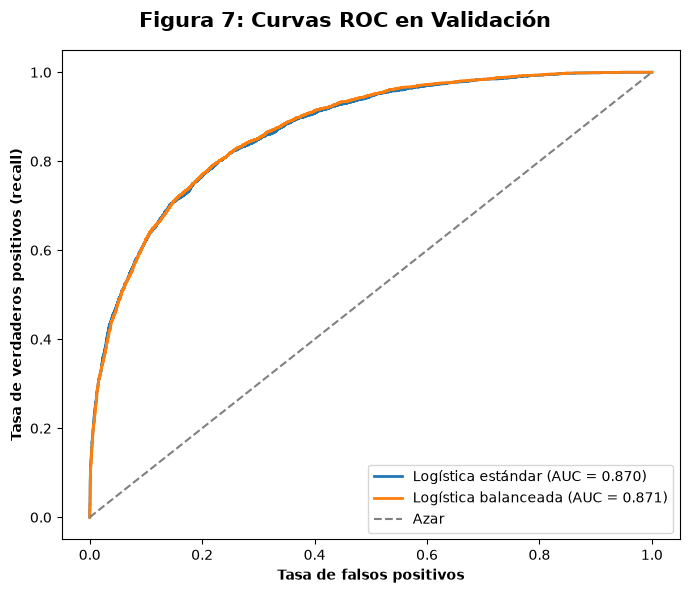

In [92]:
fig, ax = plt.subplots(figsize = (7, 6))

for nombre, probas in probabilidades.items():
    tasa_fp, tasa_vp, _ = roc_curve(y_val_cod, probas['Validación'])
    auc = roc_auc_score(y_val_cod, probas['Validación'])
    ax.plot(tasa_fp, tasa_vp, linewidth = 2, label = f"{nombre} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], color = 'gray', linestyle = '--', label = 'Azar')
ax.set_xlabel('Tasa de falsos positivos', fontweight = 'bold')
ax.set_ylabel('Tasa de verdaderos positivos (recall)', fontweight = 'bold')
ax.legend()

plt.suptitle('Figura 7: Curvas ROC en Validación', fontweight = 'bold', fontsize = 15)
plt.tight_layout()
plt.show()

Las dos curvas quedan prácticamente superpuestas y muy por encima de la diagonal, con un AUC de 0,87. Una forma de interpretarlo: si se toma al azar un día en que llovió y uno en que no, el modelo le asigna mayor probabilidad de lluvia al primero el 87% de las veces.

Que las curvas coincidan confirma lo visto en las métricas: `class_weight = 'balanced'` no hace que el modelo distinga mejor los días de lluvia, sino que desplaza sus probabilidades hacia arriba. El mismo efecto se puede lograr con el modelo estándar bajando el umbral.

### Elección del umbral

El umbral de 0,5 no tiene por qué ser el mejor. Es el valor natural cuando ambas clases son igual de frecuentes y ambos errores cuestan lo mismo, pero acá ninguna de las dos cosas se cumple.

El umbral se elige en el conjunto de validación, con dos criterios habituales:

- **Máximo F1**: el umbral que mejor equilibra precision y recall.
- **Índice de Youden**: el umbral que maximiza la diferencia entre la tasa de verdaderos positivos y la de falsos positivos. Gráficamente, es el punto de la curva ROC más alejado de la diagonal. Prioriza detectar lluvias aunque aumenten las falsas alarmas.

In [93]:
resumen_umbrales = []

for nombre, probas in probabilidades.items():
    proba_val = probas['Validación']

    # Índice de Youden: máximo de (tasa de VP - tasa de FP)
    tasa_fp, tasa_vp, umbrales_roc = roc_curve(y_val_cod, proba_val)
    umbral_youden = umbrales_roc[np.argmax(tasa_vp - tasa_fp)]

    # Máximo F1 a partir de la curva precision-recall
    precision, recall, umbrales_pr = precision_recall_curve(y_val_cod, proba_val)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    umbral_f1 = umbrales_pr[np.argmax(f1[:-1])]

    for criterio, umbral in [('0,5 (por defecto)', 0.5), ('Máximo F1', umbral_f1), ('Youden', umbral_youden)]:
        fila = {'Modelo': nombre, 'Criterio': criterio, 'Umbral': umbral}
        fila.update(calcular_metricas(y_val_cod, proba_val, umbral))
        resumen_umbrales.append(fila)

resumen_umbrales = pd.DataFrame(resumen_umbrales).set_index(['Modelo', 'Criterio'])
resumen_umbrales.drop(columns = ['AUC-ROC', 'AUC-PR']).round(3)

Umbral  Accuracy  Precision  Recall  \
Modelo               Criterio                                                 
Logística estándar   0,5 (por defecto)   0.500     0.852      0.747   0.455   
                     Máximo F1           0.251     0.824      0.569   0.703   
                     Youden              0.168     0.776      0.483   0.801   
Logística balanceada 0,5 (por defecto)   0.500     0.812      0.543   0.727   
                     Máximo F1           0.595     0.838      0.611   0.648   
                     Youden              0.424     0.785      0.495   0.788   

                                           F1  Balanced accuracy  
Modelo               Criterio                                     
Logística estándar   0,5 (por defecto)  0.565              0.707  
                     Máximo F1          0.629              0.780  
                     Youden             0.603              0.785  
Logística balanceada 0,5 (por defecto)  0.621              0.781  
                     Máximo F1          0.629              0.769  
                     Youden             0.608              0.786

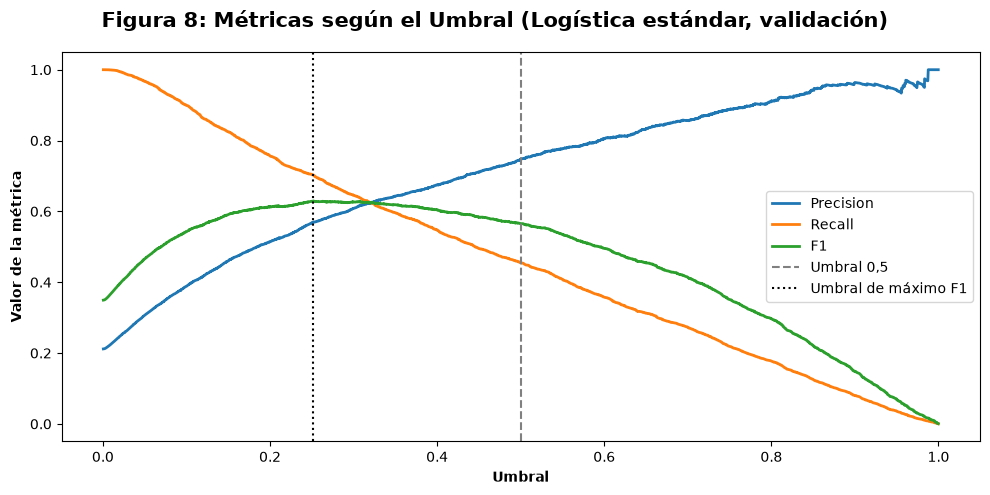

In [94]:
# Precision, recall y F1 del modelo estándar para cada umbral
proba_val = probabilidades['Logística estándar']['Validación']
precision, recall, umbrales_pr = precision_recall_curve(y_val_cod, proba_val)
f1 = 2 * precision * recall / (precision + recall + 1e-12)

fig, ax = plt.subplots(figsize = (10, 5))
ax.plot(umbrales_pr, precision[:-1], label = 'Precision', linewidth = 2)
ax.plot(umbrales_pr, recall[:-1], label = 'Recall', linewidth = 2)
ax.plot(umbrales_pr, f1[:-1], label = 'F1', linewidth = 2)
ax.axvline(0.5, color = 'gray', linestyle = '--', label = 'Umbral 0,5')
ax.axvline(umbrales_pr[np.argmax(f1[:-1])], color = 'black', linestyle = ':', label = 'Umbral de máximo F1')
ax.set_xlabel('Umbral', fontweight = 'bold')
ax.set_ylabel('Valor de la métrica', fontweight = 'bold')
ax.legend()

plt.suptitle('Figura 8: Métricas según el Umbral (Logística estándar, validación)', fontweight = 'bold', fontsize = 15)
plt.tight_layout()
plt.show()

En ambos modelos, 0,5 no es el mejor umbral.

Para la regresión logística estándar, el umbral de máximo F1 es 0,25: al bajarlo, el recall sube de 0,455 a 0,703 y el F1 de 0,565 a 0,629. La Figura 8 muestra el porqué: a medida que baja el umbral, el modelo marca más días como lluvia, el recall crece y la precision cae, y el F1 es máximo en la zona donde ambas curvas se acercan: entre 0,25 y 0,32 se mantiene casi plano. El criterio de Youden baja el umbral aún más (0,17), con un recall de 0,80 a costa de más falsas alarmas.

Para la versión balanceada pasa lo inverso: su umbral de máximo F1 es 0,60, por encima de 0,5, porque sus probabilidades ya están desplazadas hacia arriba.

Lo más importante es que, con su umbral óptimo, **ambos modelos alcanzan el mismo F1 (0,629)**. Es la confirmación de que balancear las clases y ajustar el umbral son dos caminos para lo mismo.

Como umbral se adopta el de máximo F1, porque el F1 es la métrica que equilibra los dos tipos de error sin depender del desbalance. Si el uso del pronóstico hiciera mucho más grave no anticipar una lluvia que una falsa alarma, convendría el criterio de Youden.

Como estos umbrales se eligieron mirando validación, las métricas obtenidas con ellos en ese mismo conjunto son algo optimistas. La evaluación sin sesgo se hará sobre test, en la comparación final de modelos.

### ¿Se consiguió un buen fitting?

Las métricas en train y validación son muy parecidas. La AUC-ROC de la regresión logística estándar pasa de 0,873 a 0,870, y la de la balanceada de 0,873 a 0,871. El F1 baja unos pocos centésimos. El modelo **no está sobreajustado**: lo que aprendió en train se mantiene en datos de un año que no vio.

El desempeño, en cambio, es moderado: incluso con el umbral óptimo, el F1 no supera 0,63, y aproximadamente uno de cada tres días de lluvia sigue sin detectarse. La regresión logística separa las clases con una frontera lineal, y es probable que la relación entre las variables climáticas y la lluvia del día siguiente sea más compleja. Hay, por lo tanto, cierto **subajuste**, que se intentará mejorar con la optimización de hiperparámetros y con modelos más flexibles en los próximos ítems.